In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [3]:
from google.colab import files
import pandas as pd

# Upload the dataset
uploaded = files.upload()

Saving housing_clean.csv to housing_clean.csv


In [4]:
# Read the uploaded CSV file
df = pd.read_csv('housing_clean.csv')

# Display the first 5 rows
df.head()

,Area,Rooms,Age,Location_Score,Price
0,778,1,6,3,5081030
1,2148,4,27,8,11863210
2,1909,3,3,5,11371453
3,1478,3,16,3,9079771
4,1466,3,14,4,7502204


In [6]:
from re import X
# One input feature: Area
X_simple = df[['Area']]
y = df['Price']

X_tr, X_te, y_tr, y_te = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

model_simple = LinearRegression()
model_simple.fit(X_tr, y_tr)
pred_simple = model_simple.predict(X_te)

print('SIMPLE REGRESSION')
print('R²:', round(r2_score(y_te, pred_simple), 3))
print('RMSE:', round(np.sqrt(mean_squared_error(y_te, pred_simple)), 2))

SIMPLE REGRESSION
R²: 0.939
RMSE: 809207.7


In [10]:
# Four input features
X_multi = df[['Area', 'Rooms', 'Age', 'Location_Score']]

X_tr2, X_te2, y_tr2, y_te2 = train_test_split(
    X_multi, y, test_size=0.2, random_state=42
)

model_multi = LinearRegression()
model_multi.fit(X_tr2, y_tr2)
pred_multi = model_multi.predict(X_te2)

print('MULTIPLE REGRESSION')
print('R²:', round(r2_score(y_te2, pred_multi), 3))
print('RMSE:', round(np.sqrt(mean_squared_error(y_te2, pred_multi)), 2))

MULTIPLE REGRESSION
R²: 0.977
RMSE: 495063.19


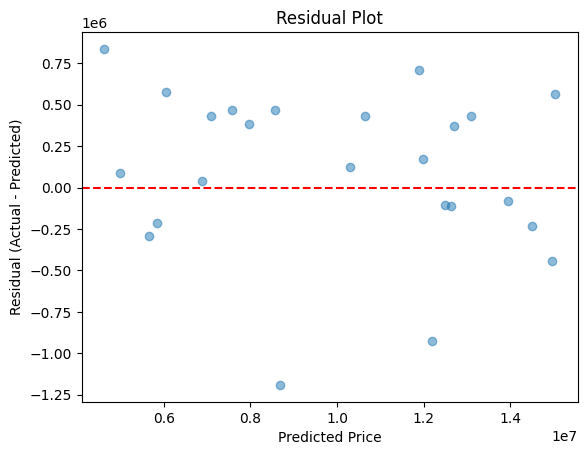

In [11]:
residuals = y_te2 - pred_multi

plt.scatter(pred_multi, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Price')
plt.ylabel('Residual (Actual - Predicted)')
plt.title('Residual Plot')
plt.show()